In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import warnings
warnings.filterwarnings("ignore")

In [ ]:
df=pd.read_csv("housing.csv")

In [ ]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [ ]:
df.tail()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


In [ ]:
df.shape

(20640, 10)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [ ]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [ ]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')

In [ ]:
df.isnull().sum()           # null values

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [ ]:
df["total_bedrooms"].fillna(df["total_bedrooms"].median(), inplace=True)

In [ ]:
df.duplicated().sum()

np.int64(0)

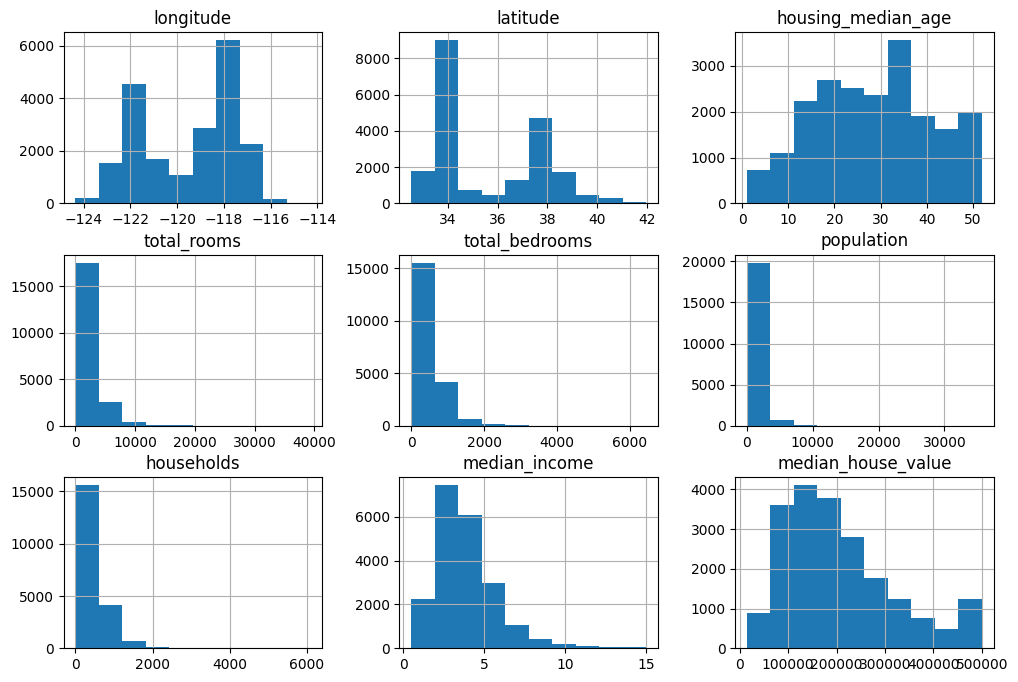

In [ ]:
df.hist(figsize=(12,8))
plt.show()

In [ ]:
df.drop("ocean_proximity",axis=1,inplace=True)

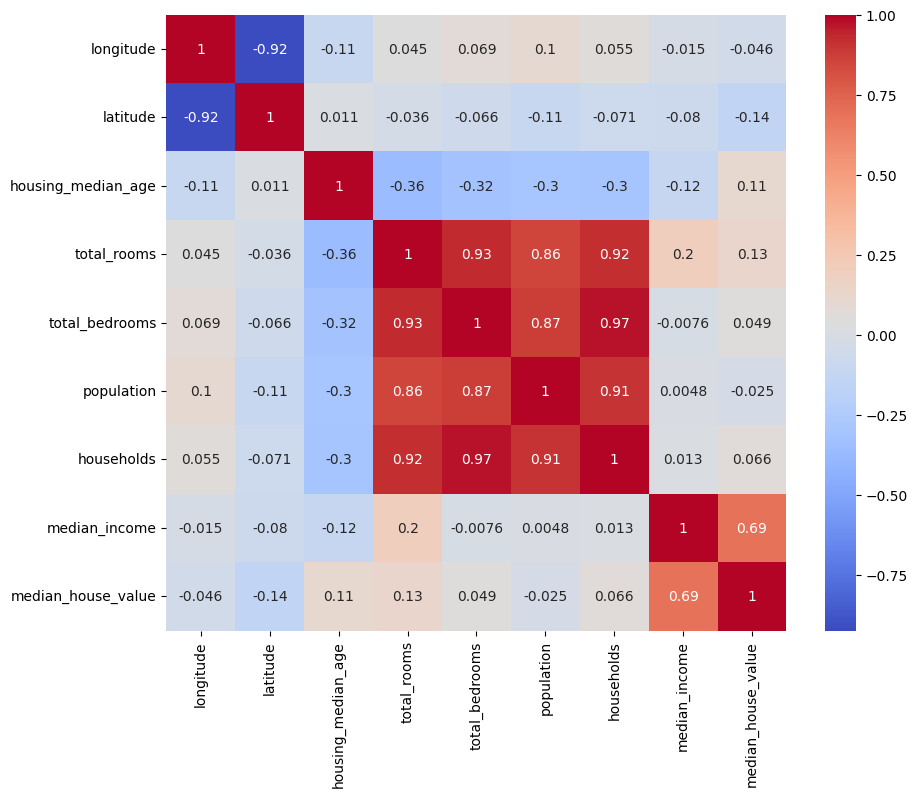

In [ ]:
plt.figure(figsize=(10,8))
numeric_df = df.select_dtypes(include=['number'])

sns.heatmap(numeric_df.corr(),
            annot=True,
            cmap='coolwarm')
plt.show()

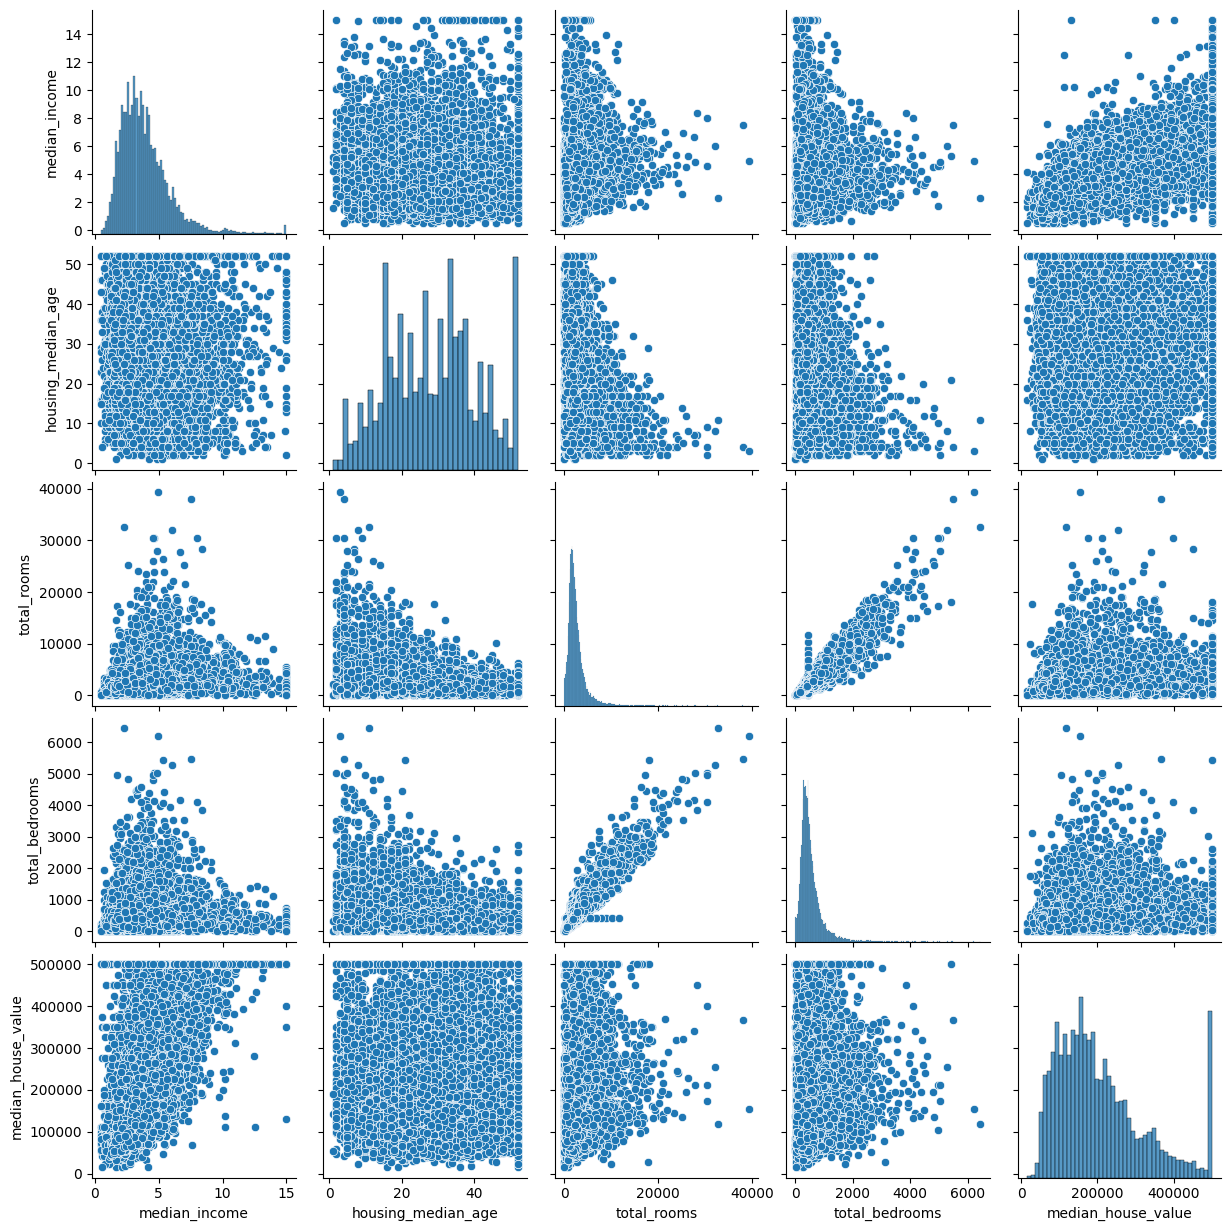

In [ ]:
sns.pairplot(df[['median_income',
                 'housing_median_age',
                 'total_rooms',
                 'total_bedrooms',
                 'median_house_value']])

In [ ]:
# single linear regres
X = df[["median_income"]]
y = df["median_house_value"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

slr = LinearRegression()
slr.fit(X_train, y_train)

LinearRegression()

In [ ]:
y_pred=slr.predict(X_test)

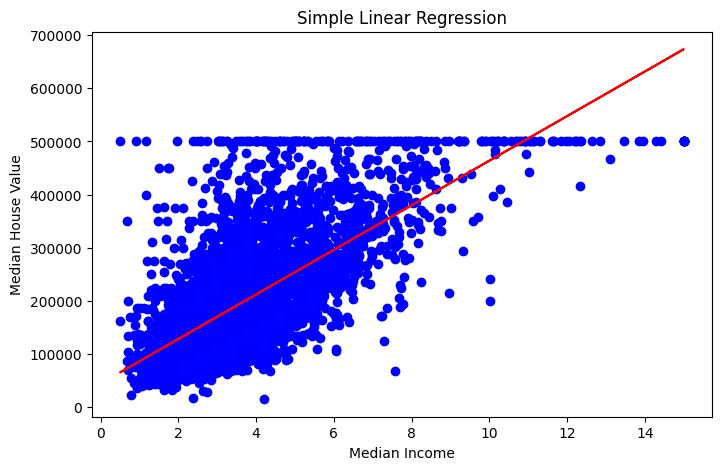

In [ ]:
plt.figure(figsize=(8,5))
plt.scatter(X_test, y_test, color='blue')
plt.plot(X_test, y_pred, color='red')
plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.title("Simple Linear Regression")
plt.show()

In [ ]:
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
rmse=np.sqrt(mse)
r2=r2_score(y_test,y_pred)

print("Mean absolute error: ",mae)
print("Mean squared error: ",mse)
print("Root mean squared error: ",rmse)
print("R2 score: ",r2)

Mean absolute error:  62990.86530093761
Mean squared error:  7091157771.76555
Root mean squared error:  84209.01241414454
R2 score:  0.45885918903846656


### Multiple linear regression

In [ ]:
X = df.drop('median_house_value', axis=1)
y = df['median_house_value']

In [ ]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
mlr = LinearRegression()
mlr.fit(X_train,y_train)

LinearRegression()

In [ ]:
# Impute missing values in X_test before prediction
# Calculate the median of 'total_bedrooms' from the training data (X_train)
median_total_bedrooms_train = X_train['total_bedrooms'].median()

# Create a copy of X_test to avoid modifying the original and fill its missing values
X_test_imputed = X_test.copy()
X_test_imputed['total_bedrooms'].fillna(median_total_bedrooms_train, inplace=True)

# Now predict with the imputed test set
y_pred = mlr.predict(X_test_imputed)

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R-squared:", r2)

Mean Absolute Error: 51810.48362804276
Mean Squared Error: 5059928371.1653385
Root Mean Squared Error: 71133.17349286012
R-squared: 0.613866475643519


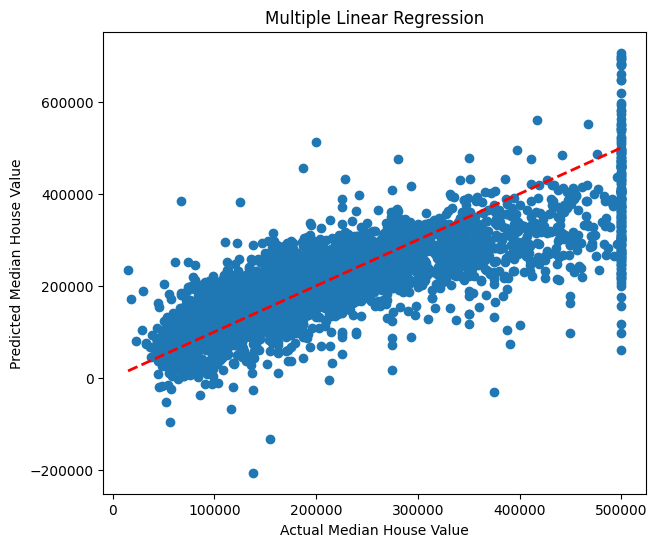

In [ ]:
plt.figure(figsize=(7,6))
plt.scatter(y_test, y_pred)

plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], linestyle='--', linewidth=2, color='red')
plt.xlabel("Actual Median House Value")
plt.ylabel("Predicted Median House Value")
plt.title("Multiple Linear Regression")
plt.show()

## Hyperparameter Tuning

In [ ]:
lr=LinearRegression()

In [ ]:
lr_params={
    'fit_intercept':[True,False],
    'positive':[True,False]
}

In [ ]:
from sklearn.model_selection import GridSearchCV
grid_search = GridSearchCV(estimator=lr,
                           param_grid=lr_params,
                           cv=5,
                           scoring = 'r2',
                           n_jobs=-1)

In [ ]:
grid_search.fit(X_train,y_train)

GridSearchCV(cv=5, estimator=LinearRegression(), n_jobs=-1,
             param_grid={'fit_intercept': [True, False],
                         'positive': [True, False]},
             scoring='r2')

In [ ]:
print("Best parameters: ")
print(grid_search.best_params_)

Best parameters: 
{'fit_intercept': True, 'positive': False}


In [ ]:
{ 'fit_intercept': True,
  'positive': False
}

{'fit_intercept': True, 'positive': False}

In [ ]:
print("Best cross validation score: ")
print(grid_search.best_score_)

Best cross validation score: 
0.6381316399361421


In [ ]:
y_pred= best_model.predict(X_test)

In [ ]:
mae = mean_absolute_error(y_test,y_pred)
mse = mean_squared_error(y_test,y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test,y_pred)

print("MAE: ",mae)
print("MSE: ",mse)
print("RMSE: ",rmse)
print("R2: ",r2)

MAE:  51810.48362804276
MSE:  5059928371.1653385
RMSE:  71133.17349286012
R2:  0.613866475643519


In [ ]:
print(best_model)

LinearRegression()


In [ ]:
results=grid_search.cv_results_

for mean_score,params in zip(results["mean_test_score"],results["params"]):
    print(params, "R2 = ", round(mean_score,4))

{'fit_intercept': True, 'positive': True} R2 =  0.5273
{'fit_intercept': True, 'positive': False} R2 =  0.6381
{'fit_intercept': False, 'positive': True} R2 =  0.5271
{'fit_intercept': False, 'positive': False} R2 =  0.5804


## Ridge Regression

In [ ]:
from sklearn.model_selection import GridSearchCV

In [ ]:
from sklearn.linear_model import Ridge

In [ ]:
ridge=Ridge()
ridge.fit(X_train,y_train)
ridge_pred=ridge.predict(X_test)
print("Default ridge R2: ", r2_score(y_test,ridge_pred))

Default ridge R2:  0.6138686241889177


In [ ]:
param_grid={ 'alpha':[0.001,0.01,0.1,1,10,100]}

In [ ]:
grid_ridge = GridSearchCV(estimator=Ridge(),
                           param_grid=param_grid,
                           cv=5,
                           scoring = 'r2',
                           n_jobs=-1)

In [ ]:
grid_ridge.fit(X_train,y_train)

GridSearchCV(cv=5, estimator=Ridge(), n_jobs=-1,
             param_grid={'alpha': [0.001, 0.01, 0.1, 1, 10, 100]},
             scoring='r2')

In [ ]:
print("Best alpha: ",grid_ridge.best_params_)

Best alpha:  {'alpha': 10}


In [ ]:
print(grid_ridge.best_score_)

0.6381322868510149


In [ ]:
best_ridge=grid_ridge.best_estimator_
ridge_pred=best_ridge.predict(X_test)

In [ ]:
print("MAE: ",mean_absolute_error(y_test,ridge_pred))
print("MSE: ",mean_squared_error(y_test,ridge_pred))
print("RMSE: ",np.sqrt(mean_squared_error(y_test,ridge_pred)))
print("R2: ",r2_score(y_test,ridge_pred))

MAE:  51808.57529208945
MSE:  5059651137.843509
RMSE:  71131.22477395921
R2:  0.613887631887595


## Lasso Regression

In [ ]:
from sklearn.linear_model import Lasso

In [ ]:
param_grid={ 'alpha':[0.001,0.01,0.1,1,10]}

In [ ]:
grid_lasso = GridSearchCV(
    Lasso(max_iter=5000),
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)
grid_lasso.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=Lasso(max_iter=5000), n_jobs=-1,
             param_grid={'alpha': [0.001, 0.01, 0.1, 1, 10]}, scoring='r2')

In [ ]:
print(grid_lasso.best_params_)

{'alpha': 10}


In [ ]:
lasso_pred=grid_lasso.predict(X_test)
print(r2_score(y_test,lasso_pred))

0.6138754685544959
